# Lab 4 — Notebook 2: Data Augmentation

**Author:** Kshitij Maurya

**Goal:** balance the weakly labeled training set by creating slightly modified copies of minority-class reviews.

```
Notebook 1: Weak Labeling -> [Notebook 2: Augmentation] -> Notebook 3: Model Development
```

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

LAB_ROOT = Path.cwd().parent          # notebooks/ -> Lab4/
sys.path.insert(0, str(LAB_ROOT))

from src.config import load_config, lab_path
from src.data_validator import DataValidator
from src import utils

cfg = load_config()
FIG_DIR = lab_path(cfg["model"]["figures_dir"])
POS, NEG, ABSTAIN = cfg["labeling"]["positive"], cfg["labeling"]["negative"], cfg["labeling"]["abstain"]
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

import random
random.seed(cfg["augmentation"]["random_seed"])

### Step 1 — Load the weakly labeled reviews

In [2]:
df = utils.load_reviews(lab_path(cfg["data"]["weak_labeled"]))
df.head(3)

Loaded imdb_weak_labeled.csv: 3,114 rows, 3 columns


,text,n_words,weak_label
0,i just finished watching marigold today and i'll begin by saying that i found this dvd on the shelves of blockbuster...,558,1
1,"melvyn douglas and joan blondell co-star in ""the amazing mr. williams,"" a 1939 mystery/comedy that's quite good, alt...",243,1
2,"insignificant and low-brained (haha!) 80's horror like there are thirteen in a dozen, yet it can be considered amusi...",343,1


### Step 2 — Check class balance
Our rules fire more often on one sentiment than the other, so the weak labels are not 50/50.

In [3]:
counts = df["weak_label"].value_counts()
print(counts.rename({POS: "positive", NEG: "negative"}))
print((counts / counts.sum()).round(3).rename({POS: "positive", NEG: "negative"}))

weak_label
negative    1745
positive    1369
Name: count, dtype: int64
weak_label
negative    0.56
positive    0.44
Name: count, dtype: float64


### Step 3 — Define the augmentation functions
1. **Synonym replacement** — swap a few words for WordNet synonyms
2. **Random swap** — exchange the positions of two words
3. **Random deletion** — drop a few words

Negation words like *not* or *never* are **protected**: deleting *not* from "not good" would flip the label.

In [4]:
import nltk
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)
from nltk.corpus import wordnet

PROTECTED = set(cfg["augmentation"]["protected_words"])

def can_change(word):
    return word.isalpha() and word not in PROTECTED

def synonym_replacement(text, n=3):
    words = text.split()
    candidates = [i for i, w in enumerate(words) if can_change(w) and len(w) > 3]
    random.shuffle(candidates)
    replaced = 0
    for i in candidates:
        synonyms = {l.name().lower() for s in wordnet.synsets(words[i]) for l in s.lemmas()}
        synonyms = [s for s in synonyms if s.isalpha() and s != words[i]]
        if synonyms:
            words[i] = random.choice(sorted(synonyms))
            replaced += 1
        if replaced == n:
            break
    return " ".join(words)

def random_swap(text, n=2):
    words = text.split()
    positions = [i for i, w in enumerate(words) if can_change(w)]
    for _ in range(n):
        if len(positions) < 2:
            break
        i, j = random.sample(positions, 2)
        words[i], words[j] = words[j], words[i]
    return " ".join(words)

def random_deletion(text, p=0.1):
    words = text.split()
    kept = [w for w in words if not can_change(w) or random.random() > p]
    return " ".join(kept) if kept else text

AUGMENTERS = [synonym_replacement, random_swap, random_deletion]

### Step 4 — Try them on one short review

In [5]:
example = df.loc[df["n_words"].between(30, 60), "text"].iloc[0]
print("ORIGINAL :", example, "\n")
for fn in AUGMENTERS:
    print(f"{fn.__name__.upper():20}:", fn(example), "\n")

ORIGINAL : william h. macy is brilliant as everyman caught in a desperate situation. starts off with a bang and never lets up. twists and surprises are fresh, unpredictable. use of film noir clips and frequent quotes and references to 30's and 40's flicks makes this a delightful "must" for movie buffs. 



SYNONYM_REPLACEMENT : william h. macy is magnificent as everyman caught in a desperate situation. starts off with a bang and never lets up. twists and surprises are fresh, unpredictable. use of film noir clips and patronise quote and references to 30's and 40's flicks makes this a delightful "must" for movie buffs. 

RANDOM_SWAP         : starts h. macy is brilliant as everyman caught in a desperate situation. william off with a bang and never lets up. delightful and surprises are fresh, unpredictable. use of film noir clips and frequent quotes and references to 30's and 40's flicks makes this a twists "must" for movie buffs. 

RANDOM_DELETION     : william h. macy is brilliant as in a desperate situation. starts off with a bang and never lets up. twists and surprises fresh, unpredictable. use of noir clips and frequent quotes and references to 30's and 40's flicks makes this a delightful "must" for movie buffs. 



### Step 5 — Augment the minority class
We create exactly as many new minority reviews as needed to match the majority class. Each new review is a copy of a random minority review passed through one random augmenter.

In [6]:
minority, majority = counts.idxmin(), counts.idxmax()
n_needed = counts[majority] - counts[minority]
sources = df[df["weak_label"] == minority].sample(n_needed, replace=True,
                                                    random_state=cfg["augmentation"]["random_seed"])

df_aug = sources.copy()
df_aug["text"] = [random.choice(AUGMENTERS)(t) for t in sources["text"]]
df_aug["n_words"] = df_aug["text"].apply(utils.word_count)
df_aug["is_augmented"] = True
print(f"Created {len(df_aug):,} new reviews with label {minority}")

Created 376 new reviews with label 1


### Step 6 — Merge with the original data and remove duplicates

In [7]:
df["is_augmented"] = False
df_full = pd.concat([df, df_aug], ignore_index=True).drop_duplicates(subset="text").reset_index(drop=True)
print("Shape after merge:", df_full.shape)

Shape after merge: (3490, 4)


### Step 7 — Check the new balance

In [8]:
new_counts = df_full["weak_label"].value_counts()
print(new_counts.rename({POS: "positive", NEG: "negative"}))
print((new_counts / new_counts.sum()).round(3).rename({POS: "positive", NEG: "negative"}))

weak_label
positive    1745
negative    1745
Name: count, dtype: int64
weak_label
positive    0.5
negative    0.5
Name: count, dtype: float64


### Step 8 — Validate and save the augmented training set

In [9]:
validator = DataValidator(required_columns=["text", "weak_label"], text_col="text", label_col="weak_label")
validator.run(df_full)
validator.print_report()
utils.save_csv(df_full, lab_path(cfg["data"]["augmented"]))

Data validation: PASSED
  [ok] enough rows          3,490 rows (need 1)
  [ok] required columns     all present
  [ok] no missing values    0 missing cells
  [ok] no duplicate rows    0 duplicates
  [ok] text long enough     0 texts under 3 words
  [ok] class balance        1: 50.0%, 0: 50.0%
Saved 3,490 rows -> imdb_augmented.csv


### Step 9 — Before vs. after

Original reviews: 3,114 | after augmentation: 3,490 (+376)


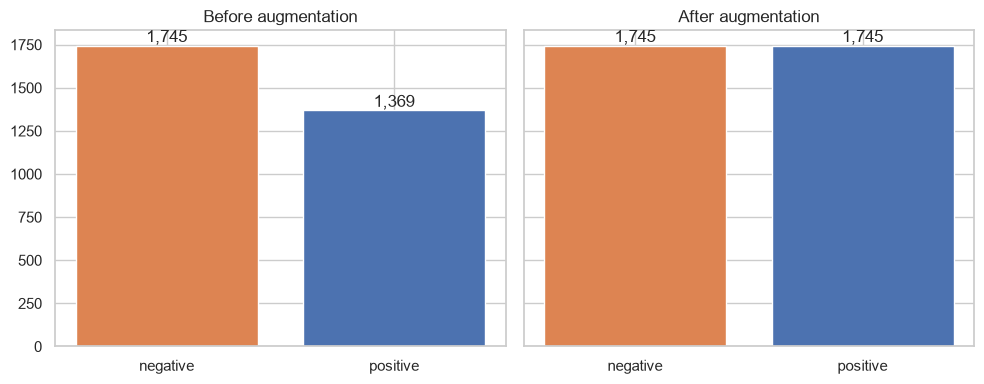

In [10]:
names = {POS: "positive", NEG: "negative"}
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, c, title in [(axes[0], counts, "Before augmentation"), (axes[1], new_counts, "After augmentation")]:
    c = c.sort_index().rename(names)
    ax.bar(c.index, c.values, color=["#DD8452", "#4C72B0"])
    ax.set_title(title)
    for i, v in enumerate(c.values):
        ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout()
utils.save_fig(fig, FIG_DIR / "02_balance.png")

print(f"Original reviews: {len(df):,} | after augmentation: {len(df_full):,} (+{len(df_full) - len(df):,})")
fig